# Figure 1 — The replicate-aware evaluation protocol
**Panel A** protocol schematic (drawn). **Panel B** same-half vs
independent-half scoring across models in K562 essential — the gap is the
leakage component the protocol removes. Data: `j22_k562_foldfrozen_centroid.csv`.

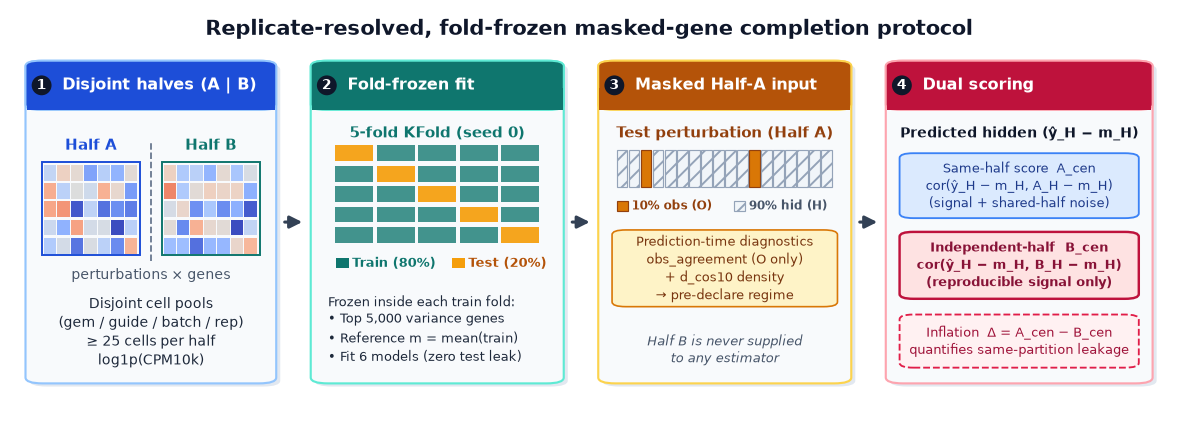

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

RES = os.path.join("..", "..", "results")
FIG = os.path.join("..", "..", "figures")
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 8.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
MODELS = ["lw", "svd20", "moppca5", "nn10", "nn50"]
MODEL_LABELS = {
    "lw": "LW shrinkage", "svd20": "SVD-20",
    "moppca5": "moPPCA-5", "nn10": "nn10", "nn50": "nn50",
}

# ---- Panel A: publication-grade protocol schematic ----
fig, ax = plt.subplots(figsize=(10.6, 3.65))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

def card(x, y, w, h, title, step, header_col, bg_col, border_col):
    ax.add_patch(FancyBboxPatch(
        (x + 0.0035, y - 0.008), w, h,
        boxstyle="round,pad=0,rounding_size=0.015",
        fc="#e2e8f0", ec="none", zorder=1))
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0,rounding_size=0.015",
        fc=bg_col, ec=border_col, lw=1.1, zorder=2))
    hh = 0.125
    ax.add_patch(FancyBboxPatch(
        (x, y + h - hh), w, hh,
        boxstyle="round,pad=0,rounding_size=0.013",
        fc=header_col, ec=border_col, lw=1.0, zorder=3))
    ax.add_patch(Rectangle(
        (x + 0.001, y + h - hh), w - 0.002, hh * 0.45,
        fc=header_col, ec="none", zorder=3))
    ax.text(x + 0.014, y + h - hh / 2, f"{step}", ha="center", va="center",
            fontsize=7.3, fontweight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=0.20", fc="#0f172a", ec="none"), zorder=4)
    ax.text(x + 0.032, y + h - hh / 2, title, ha="left", va="center",
            fontsize=8.3, fontweight="bold", color="white", zorder=4)

def conn(x1, y1, x2, y2, color="#334155"):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=13,
        lw=1.6, color=color, zorder=5))

ax.text(0.50, 0.96, "Replicate-resolved, fold-frozen masked-gene completion protocol",
        ha="center", va="center", fontsize=11.0, fontweight="bold", color="#0f172a")

cy, ch = 0.06, 0.82
c1x, c1w = 0.010, 0.218
c2x, c2w = 0.258, 0.220
c3x, c3w = 0.508, 0.220
c4x, c4w = 0.758, 0.232

card(c1x, cy, c1w, ch, "Disjoint halves (A | B)", "1", "#1d4ed8", "#f8fafc", "#93c5fd")
card(c2x, cy, c2w, ch, "Fold-frozen fit",         "2", "#0f766e", "#f8fafc", "#5eead4")
card(c3x, cy, c3w, ch, "Masked Half-A input",     "3", "#b45309", "#f8fafc", "#fcd34d")
card(c4x, cy, c4w, ch, "Dual scoring",            "4", "#be123c", "#f8fafc", "#fda4af")

conn(c1x + c1w + 0.004, 0.47, c2x - 0.004, 0.47)
conn(c2x + c2w + 0.004, 0.47, c3x - 0.004, 0.47)
conn(c3x + c3w + 0.004, 0.47, c4x - 0.004, 0.47)

# --- Card 1 visual ---
rng = np.random.default_rng(7)
base = rng.normal(0, 1.0, (5, 7))
matA = base + rng.normal(0, 0.45, base.shape)
matB = base + rng.normal(0, 0.45, base.shape)
cmap = plt.get_cmap("coolwarm")

def draw_mini_matrix(x0, y0, w, h, M, label, tag_col):
    nr, nc = M.shape
    cw, rh = w / nc, h / nr
    vmax = 2.0
    for r in range(nr):
        for c in range(nc):
            v = np.clip((M[r, c] + vmax) / (2 * vmax), 0, 1)
            ax.add_patch(Rectangle((x0 + c * cw, y0 + (nr - 1 - r) * rh),
                                   cw * 0.92, rh * 0.88, fc=cmap(v), ec="none", zorder=4))
    ax.add_patch(Rectangle((x0 - 0.0015, y0 - 0.003), w + 0.003, h + 0.005,
                           fc="none", ec=tag_col, lw=1.0, zorder=5))
    ax.text(x0 + w / 2, y0 + h + 0.025, label, ha="center", va="bottom",
            fontsize=7.6, fontweight="bold", color=tag_col, zorder=5)

draw_mini_matrix(c1x + 0.016, 0.39, 0.082, 0.23, matA, "Half A", "#1d4ed8")
draw_mini_matrix(c1x + 0.120, 0.39, 0.082, 0.23, matB, "Half B", "#0f766e")
ax.plot([c1x + 0.109, c1x + 0.109], [0.37, 0.67], ls="--", lw=0.9, color="#64748b", zorder=4)
ax.text(c1x + c1w / 2, 0.335, "perturbations × genes", ha="center", va="center",
        fontsize=7.0, color="#475569", zorder=4)
ax.text(c1x + c1w / 2, 0.19,
        "Disjoint cell pools\n(gem / guide / batch / rep)\n≥ 25 cells per half\nlog1p(CPM10k)",
        ha="center", va="center", fontsize=7.0, color="#1e293b", linespacing=1.38, zorder=4)

# --- Card 2 visual ---
bar_x, bar_w, bar_h = c2x + 0.020, c2w - 0.040, 0.040
for k in range(5):
    by = 0.625 - k * 0.052
    for seg in range(5):
        sx = bar_x + seg * (bar_w / 5)
        is_test = (seg == k)
        ax.add_patch(Rectangle((sx + 0.0015, by), bar_w / 5 - 0.003, bar_h,
                               fc="#f59e0b" if is_test else "#0f766e",
                               ec="none", alpha=0.92 if is_test else 0.78, zorder=4))
ax.text(c2x + c2w / 2, 0.695, "5-fold KFold (seed 0)", ha="center", va="center",
        fontsize=7.6, fontweight="bold", color="#0f766e", zorder=5)
ax.add_patch(Rectangle((c2x + 0.022, 0.354), 0.011, 0.024, fc="#0f766e", ec="none", zorder=5))
ax.text(c2x + 0.036, 0.365, "Train (80%)", ha="left", va="center", fontsize=6.7, color="#0f766e", fontweight="bold", zorder=5)
ax.add_patch(Rectangle((c2x + 0.123, 0.354), 0.011, 0.024, fc="#f59e0b", ec="none", zorder=5))
ax.text(c2x + 0.137, 0.365, "Test (20%)", ha="left", va="center", fontsize=6.7, color="#b45309", fontweight="bold", zorder=5)
ax.text(c2x + 0.015, 0.20,
        "Frozen inside each train fold:\n• Top 5,000 variance genes\n• Reference m = mean(train)\n• Fit 6 models (zero test leak)",
        ha="left", va="center", fontsize=6.85, color="#1e293b", linespacing=1.38, zorder=4)

# --- Card 3 visual ---
vx, vy, vw, vh = c3x + 0.016, 0.56, c3w - 0.032, 0.092
n_cells = 18
obs_idx = {2, 11}
cw = vw / n_cells
for i in range(n_cells):
    is_obs = i in obs_idx
    ax.add_patch(Rectangle(
        (vx + i * cw, vy), cw * 0.90, vh,
        fc="#d97706" if is_obs else "#f1f5f9",
        ec="#92400e" if is_obs else "#94a3b8",
        hatch="" if is_obs else "///", lw=0.6, zorder=4))
ax.text(c3x + c3w / 2, 0.695, "Test perturbation (Half A)",
        ha="center", va="center", fontsize=7.6, fontweight="bold", color="#92400e", zorder=5)
ax.add_patch(Rectangle((c3x + 0.016, 0.499), 0.010, 0.024, fc="#d97706", ec="#92400e", lw=0.6, zorder=5))
ax.text(c3x + 0.029, 0.511, "10% obs (O)", ha="left", va="center", fontsize=6.4, color="#92400e", fontweight="bold", zorder=5)
ax.add_patch(Rectangle((c3x + 0.118, 0.499), 0.010, 0.024, fc="#f1f5f9", ec="#94a3b8", hatch="///", lw=0.6, zorder=5))
ax.text(c3x + 0.131, 0.511, "90% hid (H)", ha="left", va="center", fontsize=6.4, color="#475569", fontweight="bold", zorder=5)

ax.add_patch(FancyBboxPatch(
    (c3x + 0.012, 0.255), c3w - 0.024, 0.195,
    boxstyle="round,pad=0,rounding_size=0.012",
    fc="#fef3c7", ec="#d97706", lw=0.85, zorder=4))
ax.text(c3x + c3w / 2, 0.352,
        "Prediction-time diagnostics\nobs_agreement (O only)\n+ d_cos10 density\n→ pre-declare regime",
        ha="center", va="center", fontsize=6.8, color="#78350f", linespacing=1.35, zorder=5)
ax.text(c3x + c3w / 2, 0.145,
        "Half B is never supplied\nto any estimator",
        ha="center", va="center", fontsize=6.9, style="italic", color="#475569", zorder=4)

# --- Card 4 visual ---
ax.text(c4x + c4w / 2, 0.695, "Predicted hidden (ŷ_H − m_H)",
        ha="center", va="center", fontsize=7.0, fontweight="bold", color="#0f172a", zorder=5)

ax.add_patch(FancyBboxPatch(
    (c4x + 0.012, 0.48), c4w - 0.024, 0.165,
    boxstyle="round,pad=0,rounding_size=0.012",
    fc="#dbeafe", ec="#3b82f6", lw=0.95, zorder=4))
ax.text(c4x + c4w / 2, 0.562,
        "Same-half score  A_cen\ncor(ŷ_H − m_H, A_H − m_H)\n(signal + shared-half noise)",
        ha="center", va="center", fontsize=6.75, color="#1e3a8a", linespacing=1.32, zorder=5)

ax.add_patch(FancyBboxPatch(
    (c4x + 0.012, 0.275), c4w - 0.024, 0.170,
    boxstyle="round,pad=0,rounding_size=0.012",
    fc="#fee2e2", ec="#be123c", lw=1.25, zorder=4))
ax.text(c4x + c4w / 2, 0.360,
        "Independent-half  B_cen\ncor(ŷ_H − m_H, B_H − m_H)\n(reproducible signal only)",
        ha="center", va="center", fontsize=6.75, fontweight="bold", color="#881337", linespacing=1.32, zorder=5)

ax.add_patch(FancyBboxPatch(
    (c4x + 0.012, 0.10), c4w - 0.024, 0.135,
    boxstyle="round,pad=0,rounding_size=0.012",
    fc="#fff1f2", ec="#e11d48", ls="--", lw=0.95, zorder=4))
ax.text(c4x + c4w / 2, 0.167,
        "Inflation  Δ = A_cen − B_cen\nquantifies same-partition leakage",
        ha="center", va="center", fontsize=6.7, color="#9f1239", linespacing=1.32, zorder=5)

fig.savefig(os.path.join(FIG, "fig1a_schematic.png"), bbox_inches="tight", facecolor="white")
plt.show()


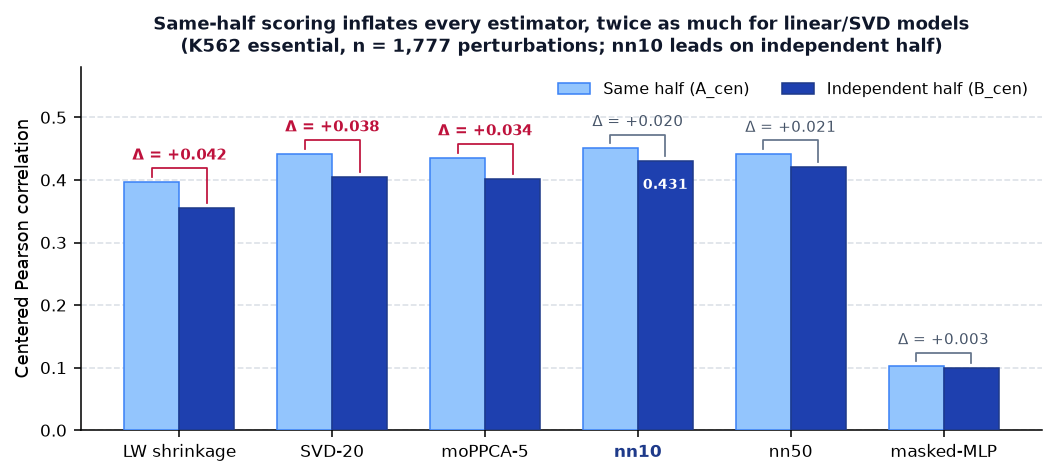

inflation per model: {'LW shrinkage': np.float64(0.042), 'SVD-20': np.float64(0.038), 'moPPCA-5': np.float64(0.034), 'nn10': np.float64(0.02), 'nn50': np.float64(0.021), 'masked-MLP': np.float64(0.003)}


In [2]:
# ---- Panel B: same-half vs independent-half (K562 essential) ----
df = pd.read_csv(os.path.join(RES, "j22_k562_foldfrozen_centroid.csv"))
dae = pd.read_csv(os.path.join(RES, "j47_k562_dae_foldfrozen.csv"))
df = df.merge(dae[["pert", "fold", "dae_A_cen", "dae_B_cen"]],
              on=["pert", "fold"], how="inner")
MODELS_B = MODELS + ["dae"]
LABELS_B = {**MODEL_LABELS, "dae": "masked-MLP"}
rows = []
for m in MODELS_B:
    rows.append({
        "model": LABELS_B[m],
        "same half": df[f"{m}_A_cen"].mean(),
        "independent half": df[f"{m}_B_cen"].mean(),
    })
t = pd.DataFrame(rows).set_index("model")

fig2, ax = plt.subplots(figsize=(7.6, 3.45))
x = np.arange(len(t))
w = 0.36
b1 = ax.bar(x - w / 2, t["same half"], width=w, color="#93c5fd",
            edgecolor="#3b82f6", linewidth=0.8, label="Same half (A_cen)", zorder=3)
b2 = ax.bar(x + w / 2, t["independent half"], width=w, color="#1e40af",
            edgecolor="#1e3a8a", linewidth=0.8, label="Independent half (B_cen)", zorder=3)

ax.yaxis.grid(True, linestyle="--", alpha=0.35, color="#94a3b8", zorder=0)
ax.set_axisbelow(True)

# Annotate inflation delta above each pair
for i, (m, row) in enumerate(t.iterrows()):
    a_val, b_val = row["same half"], row["independent half"]
    gap = a_val - b_val
    top = max(a_val, b_val)
    ax.plot([i - w / 2, i - w / 2, i + w / 2, i + w / 2],
            [a_val + 0.008, top + 0.022, top + 0.022, b_val + 0.008],
            color="#be123c" if gap >= 0.03 else "#64748b", lw=0.9, zorder=4)
    ax.text(i, top + 0.030, f"Δ = +{gap:.3f}",
            ha="center", va="bottom", fontsize=7.5,
            fontweight="bold" if gap >= 0.03 else "normal",
            color="#be123c" if gap >= 0.03 else "#475569", zorder=5)
    # highlight winner independent-half value
    if m == "nn10":
        ax.text(i + w / 2, b_val - 0.028, f"{b_val:.3f}", ha="center", va="top",
                fontsize=7.2, fontweight="bold", color="white", zorder=5)

ax.set_xticks(x)
ax.set_xticklabels(t.index, fontsize=8.8)
for tick, lbl in zip(ax.get_xticklabels(), t.index):
    if lbl == "nn10":
        tick.set_fontweight("bold")
        tick.set_color("#1e3a8a")

ax.set_ylabel("Centered Pearson correlation", fontsize=9)
ax.set_title("Same-half scoring inflates every estimator, twice as much for linear/SVD models\n"
             f"(K562 essential, n = {len(df):,} perturbations; nn10 leads on independent half)",
             fontsize=9.5, fontweight="bold", color="#0f172a", pad=8)
ax.set_ylim(0, 0.58)
ax.legend(frameon=False, loc="upper right", ncol=2, fontsize=8.3)
fig2.tight_layout()
fig2.savefig(os.path.join(FIG, "fig1b_same_vs_indep.png"), bbox_inches="tight", facecolor="white")
plt.show()
infl = (t["same half"] - t["independent half"]).round(3)
print("inflation per model:", dict(infl))
